# Implementación de una DCGAN en PyTorch para generación de rostros

**Actividad:** Generación de imágenes sintéticas mediante modelos generativos  
**Dataset:** Labeled Faces in the Wild (LFW)  
**Entorno:** Google Colab o Python local (VS Code)  
**Framework:** PyTorch

## Objetivo
Implementar una Deep Convolutional Generative Adversarial Network (DCGAN), preparar un conjunto de imágenes de rostros, entrenar de manera adversarial el generador y el discriminador, y analizar las imágenes sintéticas obtenidas.

> **Nota de reproducibilidad:** el notebook descarga LFW la primera vez que se ejecuta. Se requiere conexión a Internet para esa descarga. El entrenamiento puede realizarse en CPU, aunque se recomienda GPU. Los resultados dependen del hardware, la versión de las librerías y el tiempo de entrenamiento.

## 1. Configuración del entorno

En Google Colab, seleccionar **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU** (si está disponible).  
En VS Code, ejecutar las celdas en un entorno Python con PyTorch, Torchvision, scikit-learn, NumPy y Matplotlib instalados.

La siguiente celda instala dependencias faltantes. En Colab normalmente ya están disponibles PyTorch y Torchvision.

In [1]:
# Descomentar únicamente si alguna dependencia no está instalada.
# %pip install -q torch torchvision scikit-learn matplotlib numpy

## 2. Importación de librerías y configuración

Se fija una semilla para facilitar la reproducibilidad. La ejecución en GPU puede no ser completamente determinista en todas las operaciones, pero fijar las semillas ayuda a reducir variaciones.

In [2]:
import os
import random
import copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

import torchvision.utils as vutils
from sklearn.datasets import fetch_lfw_people

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Para mayor reproducibilidad. Puede reducir el rendimiento en algunos equipos.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Dispositivo en uso: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# Hiperparámetros principales
BATCH_SIZE = 64
IMAGE_SIZE = 64
CHANNELS = 3
LATENT_DIM = 100
GEN_FEATURES = 64
DISC_FEATURES = 64
LR = 0.0002
BETA1 = 0.5
EPOCHS = 30  # Aumentar gradualmente si el hardware y el tiempo lo permiten.

OUTPUT_DIR = Path("resultados_dcgan")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Configuración:")
print(f"Batch size={BATCH_SIZE} | Imagen={IMAGE_SIZE}x{IMAGE_SIZE} | z={LATENT_DIM}")
print(f"Épocas={EPOCHS} | Learning rate={LR}")

Dispositivo en uso: cpu
Configuración:
Batch size=64 | Imagen=64x64 | z=100
Épocas=30 | Learning rate=0.0002


## 3. Descarga y preparación del conjunto de datos LFW

Se utiliza **Labeled Faces in the Wild (LFW)**, un conjunto de fotografías de personas. Se filtran identidades con al menos cinco imágenes y se solicita la versión en color.

Las imágenes se convierten a tensores, se redimensionan a 64 × 64 píxeles y se normalizan al intervalo [-1, 1]. Esta normalización es consistente con la función `Tanh` de la última capa del generador.

**Importante:** la descarga puede tardar y requiere conexión a Internet. Si ya se descargó anteriormente, scikit-learn puede reutilizar la copia local.

In [3]:
print("Descargando y preparando el conjunto de datos LFW...")

lfw = fetch_lfw_people(
    min_faces_per_person=5,
    resize=0.5,
    color=True,
    download_if_missing=True
)

# LFW devuelve imágenes float32 con valores normalmente entre 0 y 1.
images_np = lfw.images.astype(np.float32)
print("Forma original del dataset:", images_np.shape)
print("Número de imágenes:", len(images_np))

# Convertir NHWC -> NCHW y redimensionar a 64x64.
images = torch.from_numpy(images_np).permute(0, 3, 1, 2)
images = F.interpolate(
    images,
    size=(IMAGE_SIZE, IMAGE_SIZE),
    mode="bilinear",
    align_corners=False
)

# Escalar [0,1] a [-1,1], requerido por Tanh.
images = images * 2.0 - 1.0
images = images.contiguous()

dataset = TensorDataset(images)
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

train_loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,  # Compatible con Windows, VS Code y Colab.
    drop_last=True,
    generator=loader_generator
)

real_batch = next(iter(train_loader))[0]
print(f"Total de imágenes: {len(dataset)}")
print("Forma de un batch:", real_batch.shape)
print("Rango de píxeles:", float(images.min()), "a", float(images.max()))

Descargando y preparando el conjunto de datos LFW...
Forma original del dataset: (5985, 62, 47, 3)
Número de imágenes: 5985
Total de imágenes: 5985
Forma de un batch: torch.Size([64, 3, 64, 64])
Rango de píxeles: -1.0 a 1.0


### 3.1. Visualización de imágenes reales

Esta inspección permite verificar que el dataset se cargó correctamente y que las imágenes conservan sus tres canales de color.

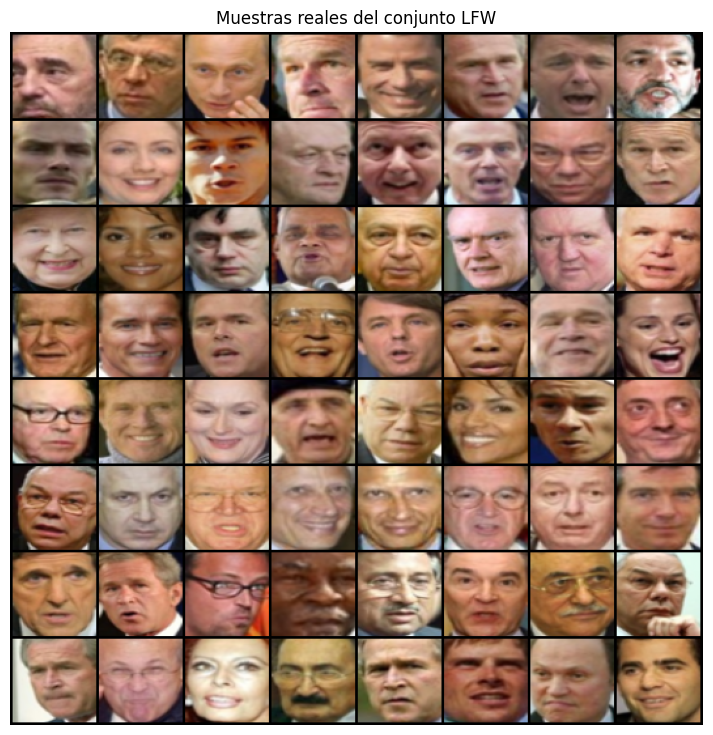

In [4]:
def show_tensor_grid(tensor_batch, title, nrow=8):
    grid = vutils.make_grid(
        tensor_batch[:nrow*nrow].detach().cpu(),
        nrow=nrow,
        normalize=True,
        value_range=(-1, 1),
        padding=2
    )
    plt.figure(figsize=(9, 9))
    plt.axis("off")
    plt.title(title)
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.show()

show_tensor_grid(real_batch, "Muestras reales del conjunto LFW")

## 4. Arquitectura de la DCGAN

Una GAN está compuesta por dos redes neuronales que compiten durante el entrenamiento:

- **Generador (Generator, G):** recibe un vector latente aleatorio `z` y produce una imagen sintética.
- **Discriminador (Discriminator, D):** recibe una imagen y estima si procede del conjunto real o del generador.

En esta implementación, el generador utiliza convoluciones transpuestas para aumentar progresivamente la resolución espacial. El discriminador utiliza convoluciones para reducirla hasta obtener una probabilidad binaria.

La dimensión del vector latente es 100. La imagen de salida tiene tres canales RGB y resolución 64 × 64.

In [5]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM, features=GEN_FEATURES, channels=CHANNELS):
        super().__init__()
        self.main = nn.Sequential(
            # Entrada: (N, latent_dim, 1, 1)
            nn.ConvTranspose2d(latent_dim, features * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(features * 8),
            nn.ReLU(True),

            # (N, 512, 4, 4) -> (N, 256, 8, 8)
            nn.ConvTranspose2d(features * 8, features * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 4),
            nn.ReLU(True),

            # (N, 256, 8, 8) -> (N, 128, 16, 16)
            nn.ConvTranspose2d(features * 4, features * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 2),
            nn.ReLU(True),

            # (N, 128, 16, 16) -> (N, 64, 32, 32)
            nn.ConvTranspose2d(features * 2, features, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features),
            nn.ReLU(True),

            # (N, 64, 32, 32) -> (N, 3, 64, 64)
            nn.ConvTranspose2d(features, channels, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.main(z)


class Discriminator(nn.Module):
    def __init__(self, features=DISC_FEATURES, channels=CHANNELS):
        super().__init__()
        self.main = nn.Sequential(
            # Entrada: (N, 3, 64, 64)
            nn.Conv2d(channels, features, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(features, features * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(features * 2, features * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(features * 4, features * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(features * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(features * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, image):
        return self.main(image).view(-1)


netG = Generator().to(device)
netD = Discriminator().to(device)

print("Generador:")
print(netG)
print("\nDiscriminador:")
print(netD)

Generador:
Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 

### 4.1. Inicialización de pesos y verificación de dimensiones

Se aplica la inicialización comúnmente utilizada en DCGAN: pesos de convolución con distribución normal centrada en cero y desviación estándar 0.02; parámetros de Batch Normalization con media 1 y desviación 0.02.

In [6]:
def weights_init(module):
    classname = module.__class__.__name__
    if "Conv" in classname:
        nn.init.normal_(module.weight.data, 0.0, 0.02)
    elif "BatchNorm" in classname:
        nn.init.normal_(module.weight.data, 1.0, 0.02)
        nn.init.constant_(module.bias.data, 0)

netG.apply(weights_init)
netD.apply(weights_init)

# Prueba de formas antes de entrenar.
with torch.no_grad():
    test_noise = torch.randn(4, LATENT_DIM, 1, 1, device=device)
    generated_test = netG(test_noise)
    discriminator_test = netD(generated_test)

print("Salida del generador:", tuple(generated_test.shape))
print("Salida del discriminador:", tuple(discriminator_test.shape))

assert generated_test.shape == (4, CHANNELS, IMAGE_SIZE, IMAGE_SIZE)
assert discriminator_test.shape == (4,)

Salida del generador: (4, 3, 64, 64)
Salida del discriminador: (4,)


## 5. Configuración del entrenamiento adversarial

Se utiliza `BCELoss` como función de pérdida y el optimizador Adam. El discriminador aprende a asignar valores cercanos a 1 a imágenes reales y cercanos a 0 a imágenes falsas. El generador intenta que el discriminador clasifique sus imágenes como reales.

Se emplea *label smoothing* para las muestras reales: en lugar de utilizar siempre la etiqueta 1.0, se utiliza 0.9. Esta técnica puede ayudar a evitar que el discriminador se vuelva excesivamente confiado.

Las pérdidas que se guardan son promedios por época, calculados sobre todos los batches, para ofrecer un seguimiento más representativo que registrar únicamente el último batch.

In [7]:
criterion = nn.BCELoss()
optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, 0.999))

fixed_noise = torch.randn(16, LATENT_DIM, 1, 1, device=device)

G_losses = []
D_losses = []
epoch_snapshots = []

REAL_LABEL = 0.9  # Label smoothing para ejemplos reales.
FAKE_LABEL = 0.0

print("Configuración del entrenamiento completada.")

Configuración del entrenamiento completada.


## 6. Entrenamiento de la DCGAN

En cada batch se realizan dos actualizaciones:

1. **Discriminador:** se calcula su pérdida frente a imágenes reales y falsas; después se actualizan sus parámetros.
2. **Generador:** se genera un nuevo lote de imágenes. El discriminador evalúa esas imágenes, pero sus parámetros se congelan temporalmente. El gradiente sigue propagándose desde la salida del discriminador hacia el generador.

El congelamiento temporal evita calcular y almacenar gradientes del discriminador durante el paso de optimización del generador, sin impedir que el gradiente atraviese esa red.

In [8]:
for epoch in range(EPOCHS):
    netG.train()
    netD.train()

    running_loss_g = 0.0
    running_loss_d = 0.0
    batches_seen = 0

    for (real_images,) in train_loader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        # -------------------------
        # 1. Actualizar Discriminador
        # -------------------------
        netD.zero_grad(set_to_none=True)

        labels_real = torch.full((batch_size,), REAL_LABEL, device=device)
        output_real = netD(real_images)
        loss_d_real = criterion(output_real, labels_real)
        loss_d_real.backward()

        noise = torch.randn(batch_size, LATENT_DIM, 1, 1, device=device)
        fake_images = netG(noise)

        labels_fake = torch.full((batch_size,), FAKE_LABEL, device=device)
        output_fake = netD(fake_images.detach())
        loss_d_fake = criterion(output_fake, labels_fake)
        loss_d_fake.backward()

        loss_d = loss_d_real + loss_d_fake
        optimizerD.step()

        # -------------------------
        # 2. Actualizar Generador
        # -------------------------
        netG.zero_grad(set_to_none=True)

        # Congelar parámetros de D durante este paso.
        for parameter in netD.parameters():
            parameter.requires_grad_(False)

        labels_generator = torch.ones(batch_size, device=device)
        output_for_generator = netD(fake_images)
        loss_g = criterion(output_for_generator, labels_generator)
        loss_g.backward()
        optimizerG.step()

        # Reactivar parámetros de D para el siguiente batch.
        for parameter in netD.parameters():
            parameter.requires_grad_(True)

        running_loss_d += loss_d.item()
        running_loss_g += loss_g.item()
        batches_seen += 1

    avg_loss_d = running_loss_d / batches_seen
    avg_loss_g = running_loss_g / batches_seen
    D_losses.append(avg_loss_d)
    G_losses.append(avg_loss_g)

    # Guardar una muestra fija al final de cada época.
    netG.eval()
    with torch.no_grad():
        samples = netG(fixed_noise).detach().cpu()
    epoch_snapshots.append(samples)

    print(
        f"Época [{epoch+1:03d}/{EPOCHS}] "
        f"| Pérdida D: {avg_loss_d:.4f} "
        f"| Pérdida G: {avg_loss_g:.4f}"
    )

print("Entrenamiento finalizado.")

Época [001/30] | Pérdida D: 0.8974 | Pérdida G: 9.4473
Época [002/30] | Pérdida D: 0.7527 | Pérdida G: 5.6621
Época [003/30] | Pérdida D: 0.6838 | Pérdida G: 5.5623
Época [004/30] | Pérdida D: 0.6788 | Pérdida G: 5.4539
Época [005/30] | Pérdida D: 0.7569 | Pérdida G: 4.8853
Época [006/30] | Pérdida D: 0.8004 | Pérdida G: 4.9069
Época [007/30] | Pérdida D: 0.7898 | Pérdida G: 4.6778
Época [008/30] | Pérdida D: 0.8140 | Pérdida G: 4.4202
Época [009/30] | Pérdida D: 0.8406 | Pérdida G: 4.5266
Época [010/30] | Pérdida D: 0.8902 | Pérdida G: 4.0045
Época [011/30] | Pérdida D: 0.8977 | Pérdida G: 3.7555
Época [012/30] | Pérdida D: 0.8752 | Pérdida G: 3.6705
Época [013/30] | Pérdida D: 0.8172 | Pérdida G: 3.7277
Época [014/30] | Pérdida D: 0.8074 | Pérdida G: 3.4983
Época [015/30] | Pérdida D: 0.8453 | Pérdida G: 3.4809
Época [016/30] | Pérdida D: 0.8550 | Pérdida G: 3.4752
Época [017/30] | Pérdida D: 0.7720 | Pérdida G: 3.4378
Época [018/30] | Pérdida D: 0.7841 | Pérdida G: 3.4301
Época [019

## 7. Evaluación del entrenamiento

Las pérdidas permiten observar la dinámica de competencia entre las redes, pero **no constituyen por sí solas una medida definitiva de calidad visual**. En una GAN es normal que las pérdidas fluctúen: el generador y el discriminador se actualizan de manera competitiva.

Se grafican los promedios por época calculados durante el entrenamiento.

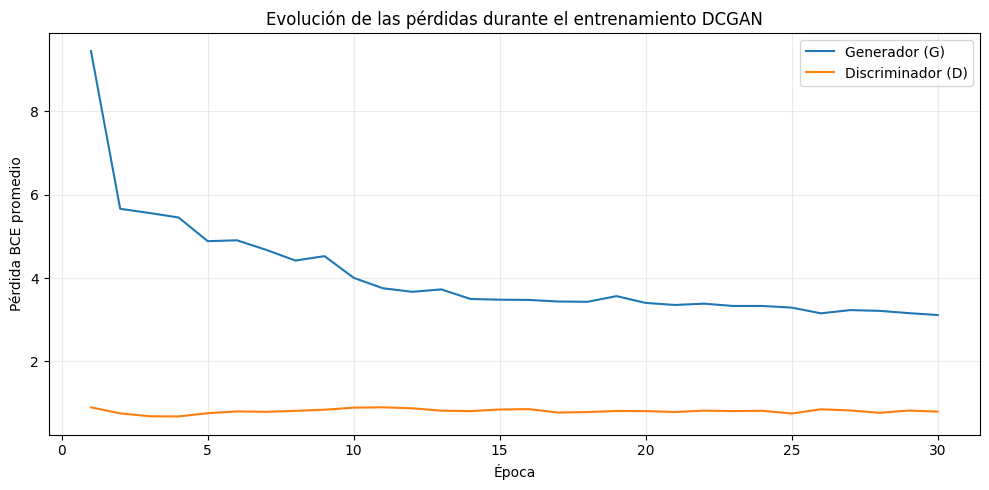

Pérdida final promedio del generador: 3.1125
Pérdida final promedio del discriminador: 0.7954


In [9]:
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(G_losses) + 1), G_losses, label="Generador (G)")
plt.plot(range(1, len(D_losses) + 1), D_losses, label="Discriminador (D)")
plt.xlabel("Época")
plt.ylabel("Pérdida BCE promedio")
plt.title("Evolución de las pérdidas durante el entrenamiento DCGAN")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "curvas_perdida.png", dpi=150)
plt.show()

print(f"Pérdida final promedio del generador: {G_losses[-1]:.4f}")
print(f"Pérdida final promedio del discriminador: {D_losses[-1]:.4f}")

## 8. Visualización de imágenes sintéticas

Se utiliza siempre el mismo vector de ruido (`fixed_noise`) para comparar cómo cambia la salida del generador a lo largo de las épocas. Las imágenes se muestran después de invertir visualmente la normalización para recuperar el intervalo de visualización.

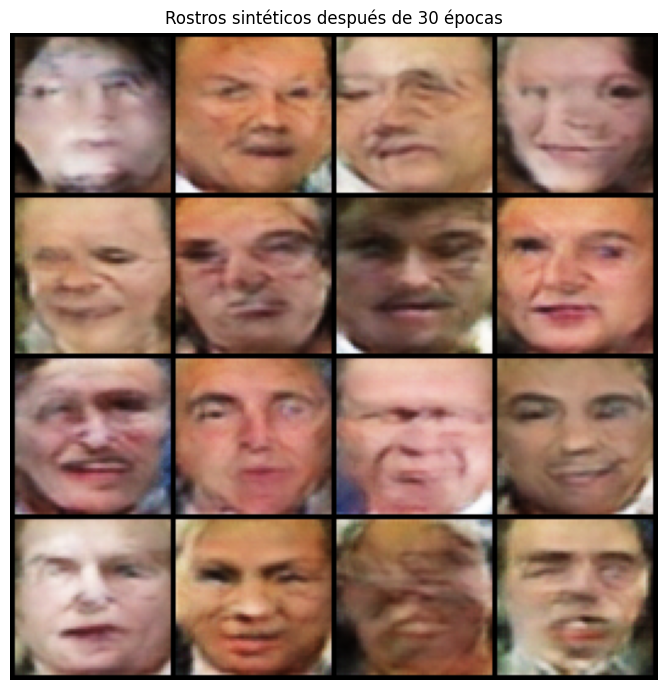

In [10]:
def show_generated(samples, title, save_path=None):
    grid = vutils.make_grid(
        samples,
        nrow=4,
        padding=2,
        normalize=True,
        value_range=(-1, 1)
    )
    plt.figure(figsize=(7, 7))
    plt.axis("off")
    plt.title(title)
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

show_generated(
    epoch_snapshots[-1],
    f"Rostros sintéticos después de {EPOCHS} épocas",
    OUTPUT_DIR / "rostros_generados_finales.png"
)

### 8.1. Comparación de muestras durante el entrenamiento

Las siguientes visualizaciones permiten observar la evolución de las mismas entradas latentes en distintas etapas.

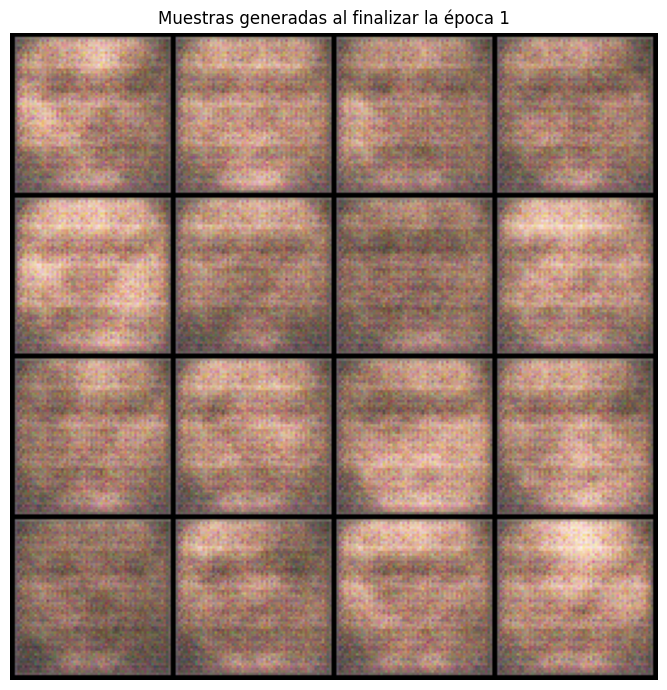

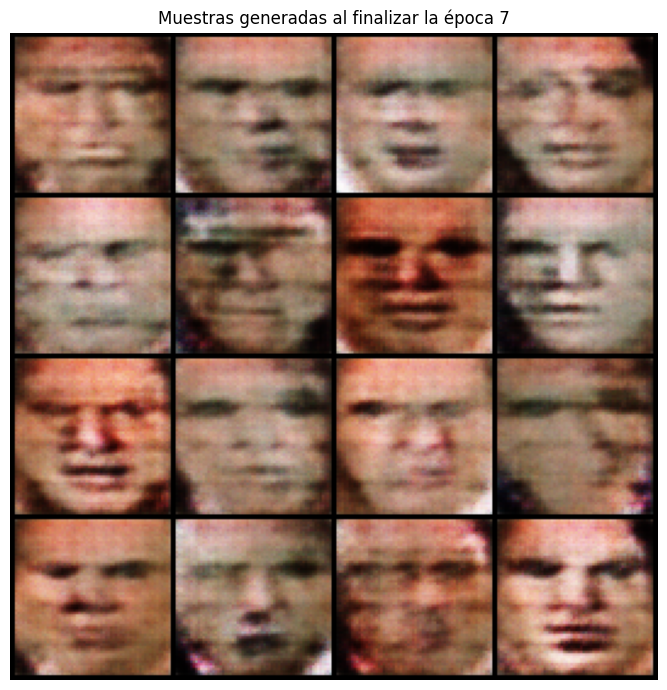

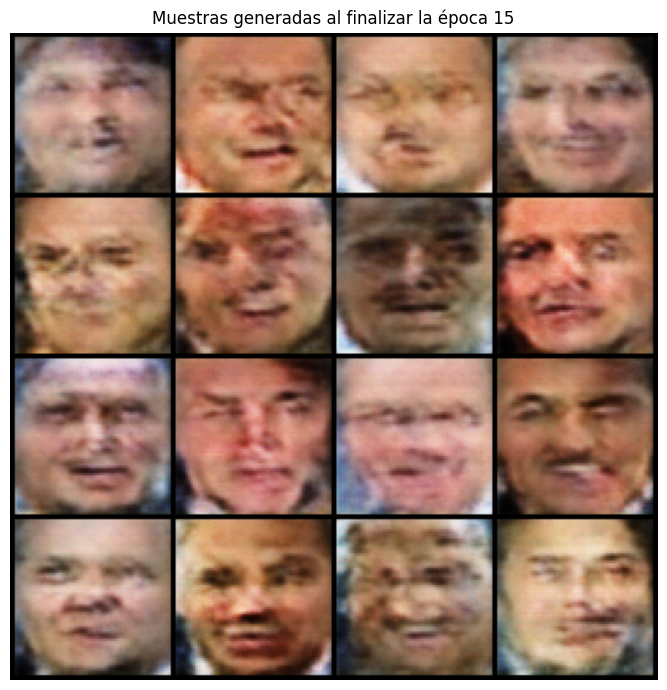

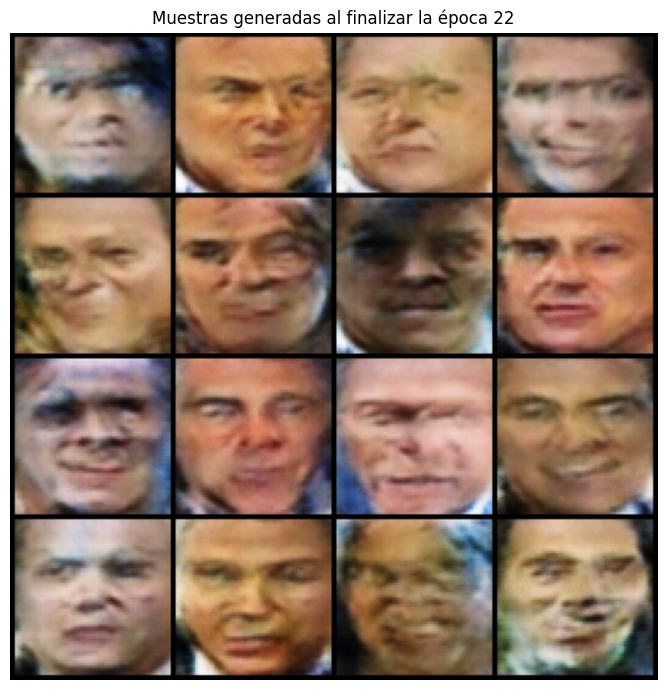

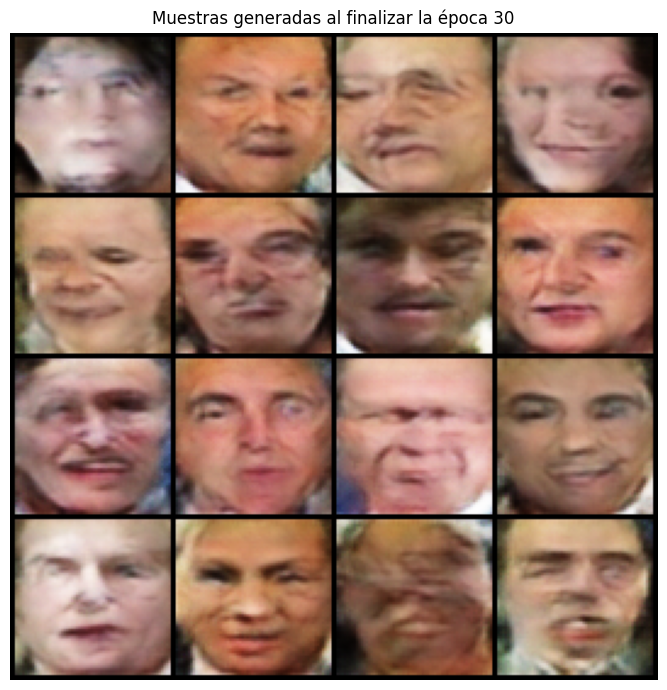

In [11]:
selected_epochs = sorted(set([
    0,
    max(0, EPOCHS // 4 - 1),
    max(0, EPOCHS // 2 - 1),
    max(0, (3 * EPOCHS) // 4 - 1),
    EPOCHS - 1
]))

for idx in selected_epochs:
    show_generated(
        epoch_snapshots[idx],
        f"Muestras generadas al finalizar la época {idx + 1}"
    )

## 9. Guardado de modelos y resultados

Se guardan los pesos del generador y del discriminador, además de un checkpoint con hiperparámetros y pérdidas. Los archivos se almacenan en la carpeta `resultados_dcgan`.

Para reutilizar el generador posteriormente, basta con reconstruir la misma arquitectura y cargar su `state_dict`.

In [12]:
generator_path = OUTPUT_DIR / "generator_dcgan.pth"
discriminator_path = OUTPUT_DIR / "discriminator_dcgan.pth"
checkpoint_path = OUTPUT_DIR / "checkpoint_dcgan.pth"

torch.save(netG.state_dict(), generator_path)
torch.save(netD.state_dict(), discriminator_path)

torch.save({
    "epoch": EPOCHS,
    "generator_state_dict": netG.state_dict(),
    "discriminator_state_dict": netD.state_dict(),
    "optimizerG_state_dict": optimizerG.state_dict(),
    "optimizerD_state_dict": optimizerD.state_dict(),
    "G_losses": G_losses,
    "D_losses": D_losses,
    "hyperparameters": {
        "batch_size": BATCH_SIZE,
        "image_size": IMAGE_SIZE,
        "latent_dim": LATENT_DIM,
        "learning_rate": LR,
        "beta1": BETA1,
        "epochs": EPOCHS,
        "seed": SEED
    }
}, checkpoint_path)

print("Archivos guardados:")
print(generator_path.resolve())
print(discriminator_path.resolve())
print(checkpoint_path.resolve())

Archivos guardados:
C:\Users\eduar\Downloads\resultados_dcgan\generator_dcgan.pth
C:\Users\eduar\Downloads\resultados_dcgan\discriminator_dcgan.pth
C:\Users\eduar\Downloads\resultados_dcgan\checkpoint_dcgan.pth


### 9.1. Prueba de carga del generador

Esta celda comprueba que los pesos guardados pueden cargarse en una nueva instancia de la arquitectura.

Modelo cargado correctamente. Forma de salida: (8, 3, 64, 64)


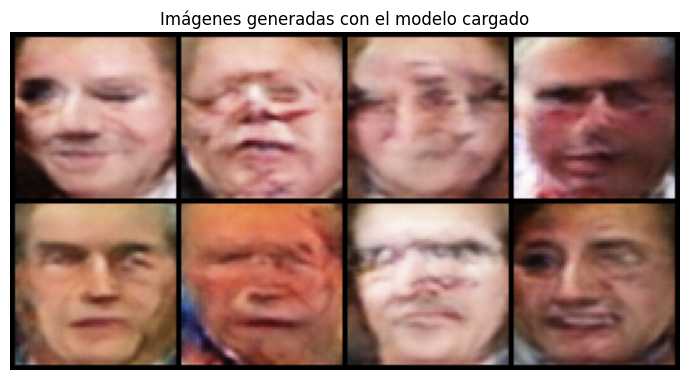

In [13]:
generator_loaded = Generator().to(device)
state_dict = torch.load(generator_path, map_location=device)
generator_loaded.load_state_dict(state_dict)
generator_loaded.eval()

with torch.no_grad():
    test_z = torch.randn(8, LATENT_DIM, 1, 1, device=device)
    loaded_samples = generator_loaded(test_z).cpu()

print("Modelo cargado correctamente. Forma de salida:", tuple(loaded_samples.shape))
show_generated(loaded_samples, "Imágenes generadas con el modelo cargado")